# Описание данных

Набор данных содержит оценки степени согласия респондентов с высказываниями,
отражающими цель потребления леденцов. Всего каждый респондент выставлял оценки по 11 высказываниям:


*   V1: Я потребляю леденцы, чтобы освежить дыхание
*   V2: Я потребляю леденцы, чтобы чувствовать себя увереннее
*   V3: Я потребляю леденцы, чтобы освежить полость рта
*   V4: Я потребляю леденцы, чтобы избавиться от неприятного вкуса во рту
*   V5: Я потребляю леденцы как заменитель других кондитерских изделий
*   V6: Я потребляю леденцы, когда мне хочется чего-нибудь сладкого
*   V7: Леденцы помогают мне сконцентрироваться
*   V8: Я потребляю леденцы, чтобы отвлечься на несколько минут и подумать
*   V9: Я потребляю леденцы для того, чтобы облегчить боль в горле
*   V10: Я потребляю леденцы для того, чтобы избавиться от заложенности носа
*   V11: Я потребляю леденцы для улучшения самочувствия

In [11]:
import numpy as np
import pandas as pd
import seaborn as sns

import matplotlib
import matplotlib.pyplot as plt
matplotlib.style.use('ggplot')
%matplotlib inline

from sklearn.cluster import DBSCAN
from sklearn import metrics

In [12]:
#import os
#os.chdir(r"C:\Users\Александра\Desktop\1 семестр\Python Аббакумов\Задачи для лабораторной 1-3\Задачи для лабораторной 1-3\задача_1_леденцы")

In [13]:
df = pd.read_csv('Леденцы.dat', sep=';')

df.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,4,5,5,5,3,3,3,3,3,3,3
1,5,4,5,5,3,3,3,3,3,3,3
2,5,5,4,5,3,3,3,3,3,3,3
3,5,4,5,5,3,3,3,3,3,3,3
4,4,5,5,5,3,3,3,3,3,3,3


In [14]:
df.shape

(338, 11)

Посмотрим в какой шкале респонденты отвечали на вопрос.

In [15]:
uniq=df.apply(lambda s: np.sort(s.unique()))
print(uniq)

   V1  V2  V3  V4  V5  V6  V7  V8  V9  V10  V11
0   2   2   2   2   2   2   2   2   2    2    2
1   3   3   3   3   3   3   3   3   3    3    3
2   4   4   4   4   4   4   4   4   4    4    4
3   5   5   5   5   5   5   5   5   5    5    5


Отсюда видно, что по каждому вопросу респонденты ставили от 2 до 5 "согласны ли они с утверждением". Можно предположить, что использовалась стандартная шкала оценивания - от 1 до 5.


# Кластеризация


In [16]:
dbscan_default = DBSCAN(eps=0.5, min_samples=5)
dbscan_default.fit(df)

unique, counts = np.unique(dbscan_default.labels_, return_counts=True)
print("Результат с параметрами по умолчанию:")
print(np.asarray((unique, counts)).T)

Результат с параметрами по умолчанию:
[[-1 60]
 [ 0 10]
 [ 1  5]
 [ 2 49]
 [ 3 12]
 [ 4  9]
 [ 5 49]
 [ 6 15]
 [ 7 10]
 [ 8  6]
 [ 9 37]
 [10 10]
 [11  5]
 [12  9]
 [13 52]]


In [31]:
eps_grid = [1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0, 5.5]
min_samples_grid = [2, 3, 4, 5, 6, 7, 8, 9, 10]

results = []

# Перебираем параметры
for eps in eps_grid:
    for min_samples in min_samples_grid:
        db = DBSCAN(eps=eps, min_samples=min_samples, metric='euclidean')
        labels = db.fit_predict(df)

        # Считаем количество кластеров (без учета шума -1) и шума
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = list(labels).count(-1)

        # Считаем силуэт (только если кластеров > 1 и это не сплошной шум)
        if n_clusters > 1:
            # Для корректного расчета силуэта исключаем шум (точки с меткой -1)
            mask = labels != -1
            if len(set(labels[mask])) > 1:
                sil_score = metrics.silhouette_score(df[mask], labels[mask])
                results.append({
                    'eps': eps,
                    'min_samples': min_samples,
                    'n_clusters': n_clusters,
                    'n_noise': n_noise,
                    'silhouette': sil_score
                })

results_df = pd.DataFrame(results)


print(results_df.sort_values(by='silhouette', ascending=False).head(20).to_string(index=False))



 eps  min_samples  n_clusters  n_noise  silhouette
 1.0           10           7       59    0.916523
 1.0            9           8       50    0.916260
 1.0            8           8       50    0.916260
 1.0            7           8       50    0.916260
 1.0            4          11       36    0.913382
 1.0            5           9       44    0.911025
 1.0            6           9       44    0.911025
 1.0            3          16       21    0.865203
 1.0            2          21       11    0.838438
 1.5            8           7       29    0.820753
 1.5           10           7       29    0.820753
 1.5            9           7       29    0.820753
 1.5            7           8       22    0.810300
 1.5            6           8       19    0.795152
 1.5            5           8       19    0.795152
 1.5            4          10       11    0.791571
 1.5            3          12        5    0.728992
 1.5            2          14        1    0.699833
 2.0            7           3  

/tmp/ipykernel_805/3677239582.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


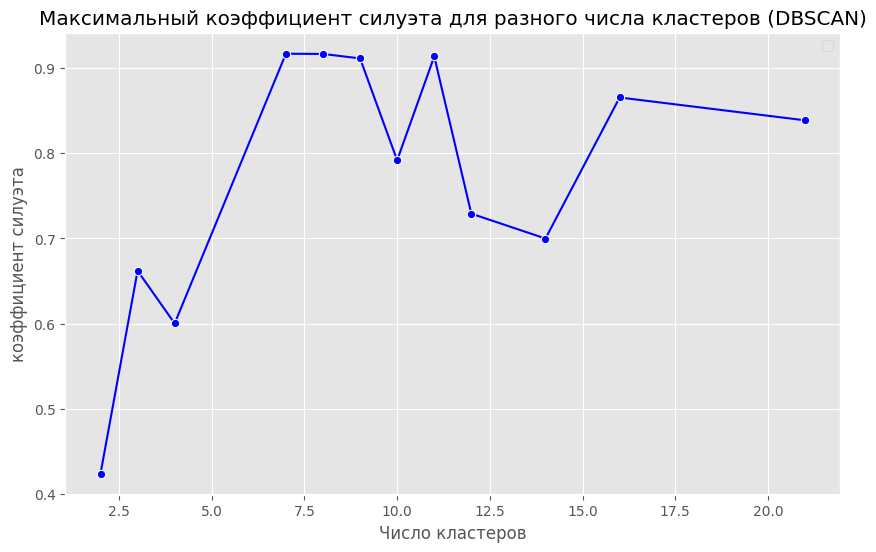

In [32]:
# Строим график
plt.figure(figsize=(10, 6))
# Берем максимальный силуэт для каждого числа кластеров
best_by_clusters = results_df.groupby('n_clusters')['silhouette'].max().reset_index()
sns.lineplot(data=best_by_clusters, x='n_clusters', y='silhouette', marker='o', color='b')

plt.title('Максимальный коэффициент силуэта для разного числа кластеров (DBSCAN)')
plt.xlabel('Число кластеров')
plt.ylabel('коэффициент силуэта')
plt.legend()
plt.grid(True)
plt.show()

In [34]:
# Проверим промежуточные значения
for eps_test in [1.6, 1.7, 1.8, 1.9, 2.0, 2.1, 2.2]:
    for min_samples_test in [3, 4, 5]:
        db_test = DBSCAN(eps=eps_test, min_samples=min_samples_test)
        labels_test = db_test.fit_predict(df)
        n_clusters = len(set(labels_test)) - (1 if -1 in labels_test else 0)
        n_noise = list(labels_test).count(-1)

        if n_clusters in [3, 4, 5]:
            print(f"eps={eps_test}, min_samples={min_samples_test} -> Кластеров: {n_clusters}, Шум: {n_noise}")

eps=1.8, min_samples=3 -> Кластеров: 5, Шум: 2
eps=1.8, min_samples=4 -> Кластеров: 5, Шум: 2
eps=1.8, min_samples=5 -> Кластеров: 4, Шум: 6
eps=1.9, min_samples=3 -> Кластеров: 5, Шум: 2
eps=1.9, min_samples=4 -> Кластеров: 5, Шум: 2
eps=1.9, min_samples=5 -> Кластеров: 4, Шум: 6
eps=2.0, min_samples=3 -> Кластеров: 4, Шум: 0
eps=2.0, min_samples=4 -> Кластеров: 4, Шум: 0
eps=2.0, min_samples=5 -> Кластеров: 3, Шум: 4
eps=2.1, min_samples=3 -> Кластеров: 4, Шум: 0
eps=2.1, min_samples=4 -> Кластеров: 4, Шум: 0
eps=2.1, min_samples=5 -> Кластеров: 3, Шум: 4
eps=2.2, min_samples=3 -> Кластеров: 4, Шум: 0
eps=2.2, min_samples=4 -> Кластеров: 4, Шум: 0
eps=2.2, min_samples=5 -> Кластеров: 3, Шум: 4


In [37]:
best_eps = 2.0
best_min_samples = 3

df_clean = df.drop(columns=['cluster', 'dist_to_center', 'cluster_kmeans', 'dbscan_cluster'], errors='ignore')

dbscan_final = DBSCAN(eps=best_eps, min_samples=best_min_samples)
df['dbscan_cluster'] = dbscan_final.fit_predict(df_clean)

print(df['dbscan_cluster'].value_counts().sort_index())

# Средние значения (считаем только по исходным признакам V1-V11)
cluster_means = df.groupby('dbscan_cluster')[df_clean.columns].mean()
display(cluster_means.round(2))

dbscan_cluster
0    110
1    104
2      4
3    120
Name: count, dtype: int64


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
dbscan_cluster,,,,,,,,,,,
0,4.85,4.80,4.84,4.68,3.04,3.04,3.00,2.99,3.07,3.05,3.05
1,2.86,2.79,2.72,2.57,2.63,2.61,2.78,2.91,4.95,4.82,4.87
2,2.00,4.00,4.00,4.00,2.00,2.00,2.00,3.00,5.00,4.75,4.75
3,3.00,2.98,2.98,2.96,3.90,3.92,3.94,3.90,2.88,2.88,2.88


После обучения финальной модели DBSCAN с параметрами eps=2.0, min_samples=3 было получено 4 кластера (без шума):

Кластер 0 теперь содержит 110 человек, где наиболее оценки: V1 (освежить дыхание), V2 (уверенность), V3 (освежить полость рта), V4 (избавиться от неприятного вкуса). То есть он совпадает с кластером, полученным методами иерархической кластеризации и k-means.

Кластер 1 содержит 104 человека и наиболее высокие оценки здесь: V9 (боль в горле), V10 (заложенность носа), V11 (улучшение самочувствия). Это по-прежнему «Лечебный» сегмент.

Кластер 2. Здесь уже видны отличия для DBCSAN. Кластер содержит всего 4 человека. По наиболее высоким оценка из опросника он близок к «Лечебному», но с необычно высокой оценкой V2–V4 (4.0). Здесь это можно принять за пограничные наблюжения.

Кластер 3 - 120 человек. Большой смешанный кластер. Средние по V5–V8 ≈ 3.9 — это «среднее арифметическое» двух разных групп: «Психологический» (V7, V8 ≈ 4.92) и «Сладкоежки» (V5, V6 ≈ 4.85). DBSCAN объединил их, потому что в пространстве признаков плотность этих групп пересекается (есть «мостики» из пограничных респондентов).

DBSCAN на этих данных выделяет три «плотных» сегмента (Свежесть, Лечебный, смешанный Психологический+Сладкоежки) и дополнительно отсекает небольшую группу из 4 наблюдений. Это происходит, так как метод не «дробит» данные на равные группы, а опирается на плотность, из-за чего родственные кластеры с размытой границей (как Психологический и Сладкоежки) могут сливаться.


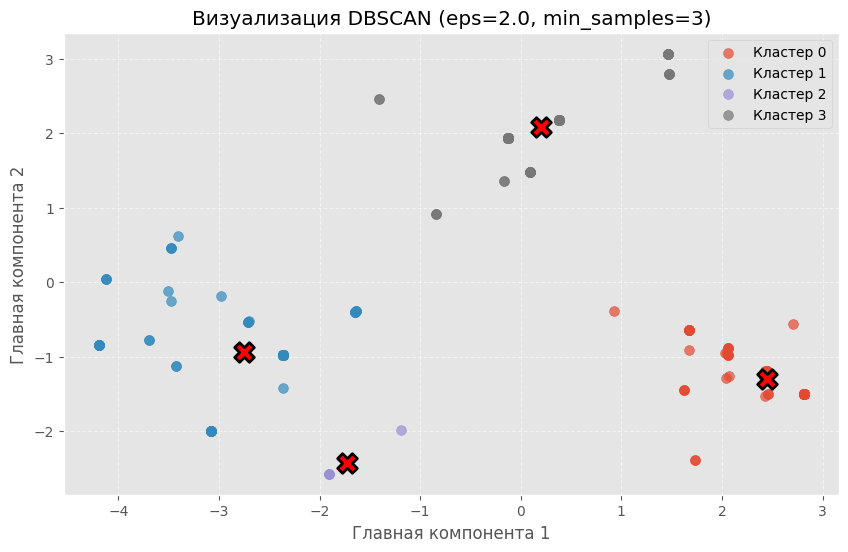

In [38]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np

# 1. Сжимаем данные до 2D (уберем метки кластеров из признаков)
X = df_clean.drop(columns=['dbscan_cluster'], errors='ignore')
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(10, 6))

# 2. Рисуем точки. Шум (-1) сделаем черными крестиками, остальные — цветными
for cluster_id in sorted(df['dbscan_cluster'].unique()):
    mask = df['dbscan_cluster'] == cluster_id
    if cluster_id == -1:
        plt.scatter(X_pca[mask, 0], X_pca[mask, 1], c='black', marker='x', s=40, alpha=0.5, label='Шум')
    else:
        plt.scatter(X_pca[mask, 0], X_pca[mask, 1], s=50, alpha=0.7, label=f'Кластер {cluster_id}')

        # 3. Рисуем центроид (среднее координат точек этого кластера на графике)
        center_pca = X_pca[mask].mean(axis=0)
        plt.scatter(center_pca[0], center_pca[1], marker='X', s=200, c='red', edgecolors='black', linewidth=2)

plt.title(f'Визуализация DBSCAN (eps={best_eps}, min_samples={best_min_samples})')
plt.xlabel('Главная компонента 1')
plt.ylabel('Главная компонента 2')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Выводы о результате работы

В ходе лабораторной работы был проведен иерархический кластерный анализ данных опроса потребителей леденцов (338 респондентов, 11 переменных).


1.  Поиск по сетке (grid search) по eps и min_samples с оценкой через Silhouette Score показал, что максимальный коэффициент силуэта достигается при малых eps (1.0), но при этом в шум уходит до 60 респондентов (18% выборки). Это неудовлетворительно с точки зрения интерпретации — терять почти пятую часть аудитории в маркетинговой задаче нежелательно.

2. После мы попробоавали использовать ручной перебор промежуточных значений (eps от 1.6 до 2.2, min_samples от 3 до 5) показал, что комбинация **eps=2.0, min_samples=3** даёт ровно 4 кластера и 0 выбросов. Эти параметры и были выбраны как компромисс между качеством силуэта и полнотой покрытия.

DBSCAN на рассматриваемых данных показал, что естественная плотностная структура данных — это **три устойчивые группы** потребителей (Свежесть, Лечебный, «сладкое/перекус»).